# Прогнозирование свойств композиционных материалов

**Задача.** По свойствам компонентов композита (связующего и армирующего наполнителя) спрогнозировать:
- модуль упругости при растяжении, ГПа;
- прочность при растяжении, МПа;
- а также рекомендовать соотношение матрица-наполнитель (нейронная сеть).

**Главный результат.** Пайплайн построен целиком (EDA, предобработка,6 моделей ML, нейронная сеть, приложение), но ни одна модель не превосходит наивный прогноз средним значением. Перестановочный тест подтверждает, что связи признаков с целевыми переменными, пригодной для прогноза, в данных нет. Вывод: для прогноза нужны другие данные, а не другая модель.

**Содержание**
1. Загрузка данных
2. Первичный осмотр
3. Разведочный анализ
4. Предобработка
5. Модели машинного обучения и сравнение с baseline
6. Перестановочный тест и взаимная информация
7. Нейронная сеть
8. Итоги

## 1. Загрузка и объединение данных
Датасет состоит из двух файлов: `X_bp.xlsx` (свойства связующего и композита) и `X_nup.xlsx` (параметры нашивки). Они объединяются по `id`, тип объединения — INNER. Код загрузки вынесен в `src/data.py` и общий для ноутбука, скрипта обучения и приложения.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()))

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from src.data import load_raw, RANDOM_STATE, TARGET_ELASTICITY, TARGET_STRENGTH, TARGET_RATIO, TARGETS

raw = load_raw()
df = raw.drop(columns='id')
print('Объединённый датасет:', df.shape)
df.head()

Объединённый датасет: (1023, 13)


,Соотношение матрица-наполнитель,"Плотность, кг/м3","модуль упругости, ГПа","Количество отвердителя, м.%","Содержание эпоксидных групп,%_2","Температура вспышки, С_2","Поверхностная плотность, г/м2","Модуль упругости при растяжении, ГПа","Прочность при растяжении, МПа","Потребление смолы, г/м2","Угол нашивки, град",Шаг нашивки,Плотность нашивки
0,1.857143,2030.0,738.736842,30.00,22.267857,100.000000,210.0,70.0,3000.0,220.0,0,4.0,57.0
1,1.857143,2030.0,738.736842,50.00,23.750000,284.615385,210.0,70.0,3000.0,220.0,0,4.0,60.0
2,1.857143,2030.0,738.736842,49.90,33.000000,284.615385,210.0,70.0,3000.0,220.0,0,4.0,70.0
3,1.857143,2030.0,738.736842,129.00,21.250000,300.000000,210.0,70.0,3000.0,220.0,0,5.0,47.0
4,2.771331,2030.0,753.000000,111.86,22.267857,284.615385,210.0,70.0,3000.0,220.0,0,5.0,57.0


## 2. Первичный осмотр

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1023 entries, 0 to 1022
Data columns (total 13 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Соотношение матрица-наполнитель       1023 non-null   float64
 1   Плотность, кг/м3                      1023 non-null   float64
 2   модуль упругости, ГПа                 1023 non-null   float64
 3   Количество отвердителя, м.%           1023 non-null   float64
 4   Содержание эпоксидных групп,%_2       1023 non-null   float64
 5   Температура вспышки, С_2              1023 non-null   float64
 6   Поверхностная плотность, г/м2         1023 non-null   float64
 7   Модуль упругости при растяжении, ГПа  1023 non-null   float64
 8   Прочность при растяжении, МПа         1023 non-null   float64
 9   Потребление смолы, г/м2               1023 non-null   float64
 10  Угол нашивки, град                    1023 non-null   int64  
 11  Шаг нашивки                 

In [3]:
df.shape

(1023, 13)

### 2.1 Проверка пропусков и дубликатов

In [4]:
print('Количество пропусков:', df.isna().sum().sum())
print('Количество полных дубликатов строк:', df.duplicated().sum())

Количество пропусков: 0
Количество полных дубликатов строк: 0


### 2.2 Описательная статистика

In [5]:
df.describe()

,Соотношение матрица-наполнитель,"Плотность, кг/м3","модуль упругости, ГПа","Количество отвердителя, м.%","Содержание эпоксидных групп,%_2","Температура вспышки, С_2","Поверхностная плотность, г/м2","Модуль упругости при растяжении, ГПа","Прочность при растяжении, МПа","Потребление смолы, г/м2","Угол нашивки, град",Шаг нашивки,Плотность нашивки
count,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000
mean,2.930366,1975.734888,739.923233,110.570769,22.244390,285.882151,482.731833,73.328571,2466.922843,218.423144,44.252199,6.899222,57.153929
std,0.913222,73.729231,330.231581,28.295911,2.406301,40.943260,281.314690,3.118983,485.628006,59.735931,45.015793,2.563467,12.350969
min,0.389403,1731.764635,2.436909,17.740275,14.254985,100.000000,0.603740,64.054061,1036.856605,33.803026,0.000000,0.000000,0.000000
25%,2.317887,1924.155467,500.047452,92.443497,20.608034,259.066528,266.816645,71.245018,2135.850448,179.627520,0.000000,5.080033,49.799212
50%,2.906878,1977.621657,739.664328,110.564840,22.230744,285.896812,451.864365,73.268805,2459.524526,219.198882,0.000000,6.916144,57.341920
75%,3.552660,2021.374375,961.812526,129.730366,23.961934,313.002106,693.225017,75.356612,2767.193119,257.481724,90.000000,8.586293,64.944961
max,5.591742,2207.773481,1911.536477,198.953207,33.000000,413.273418,1399.542362,82.682051,3848.436732,414.590628,90.000000,14.440522,103.988901


**Выводы по первичному осмотру:**
- объём выборки — 1023 наблюдения, 13 признаков (11 входных и 2 целевые переменные);
- пропуски и полные дубликаты строк отсутствуют;
- все признаки числовые;
- признак «Угол нашивки, град» принимает только два значения (0 и 90), поэтому является категориальным, несмотря на числовой тип — при предобработке его следует закодировать как категориальный.

## 3. Разведочный анализ данных (EDA)

### 3.1 Распределения признаков

Построим гистограммы распределения для каждого признака. Признак «Угол нашивки, град» исключён, так как он категориальный.

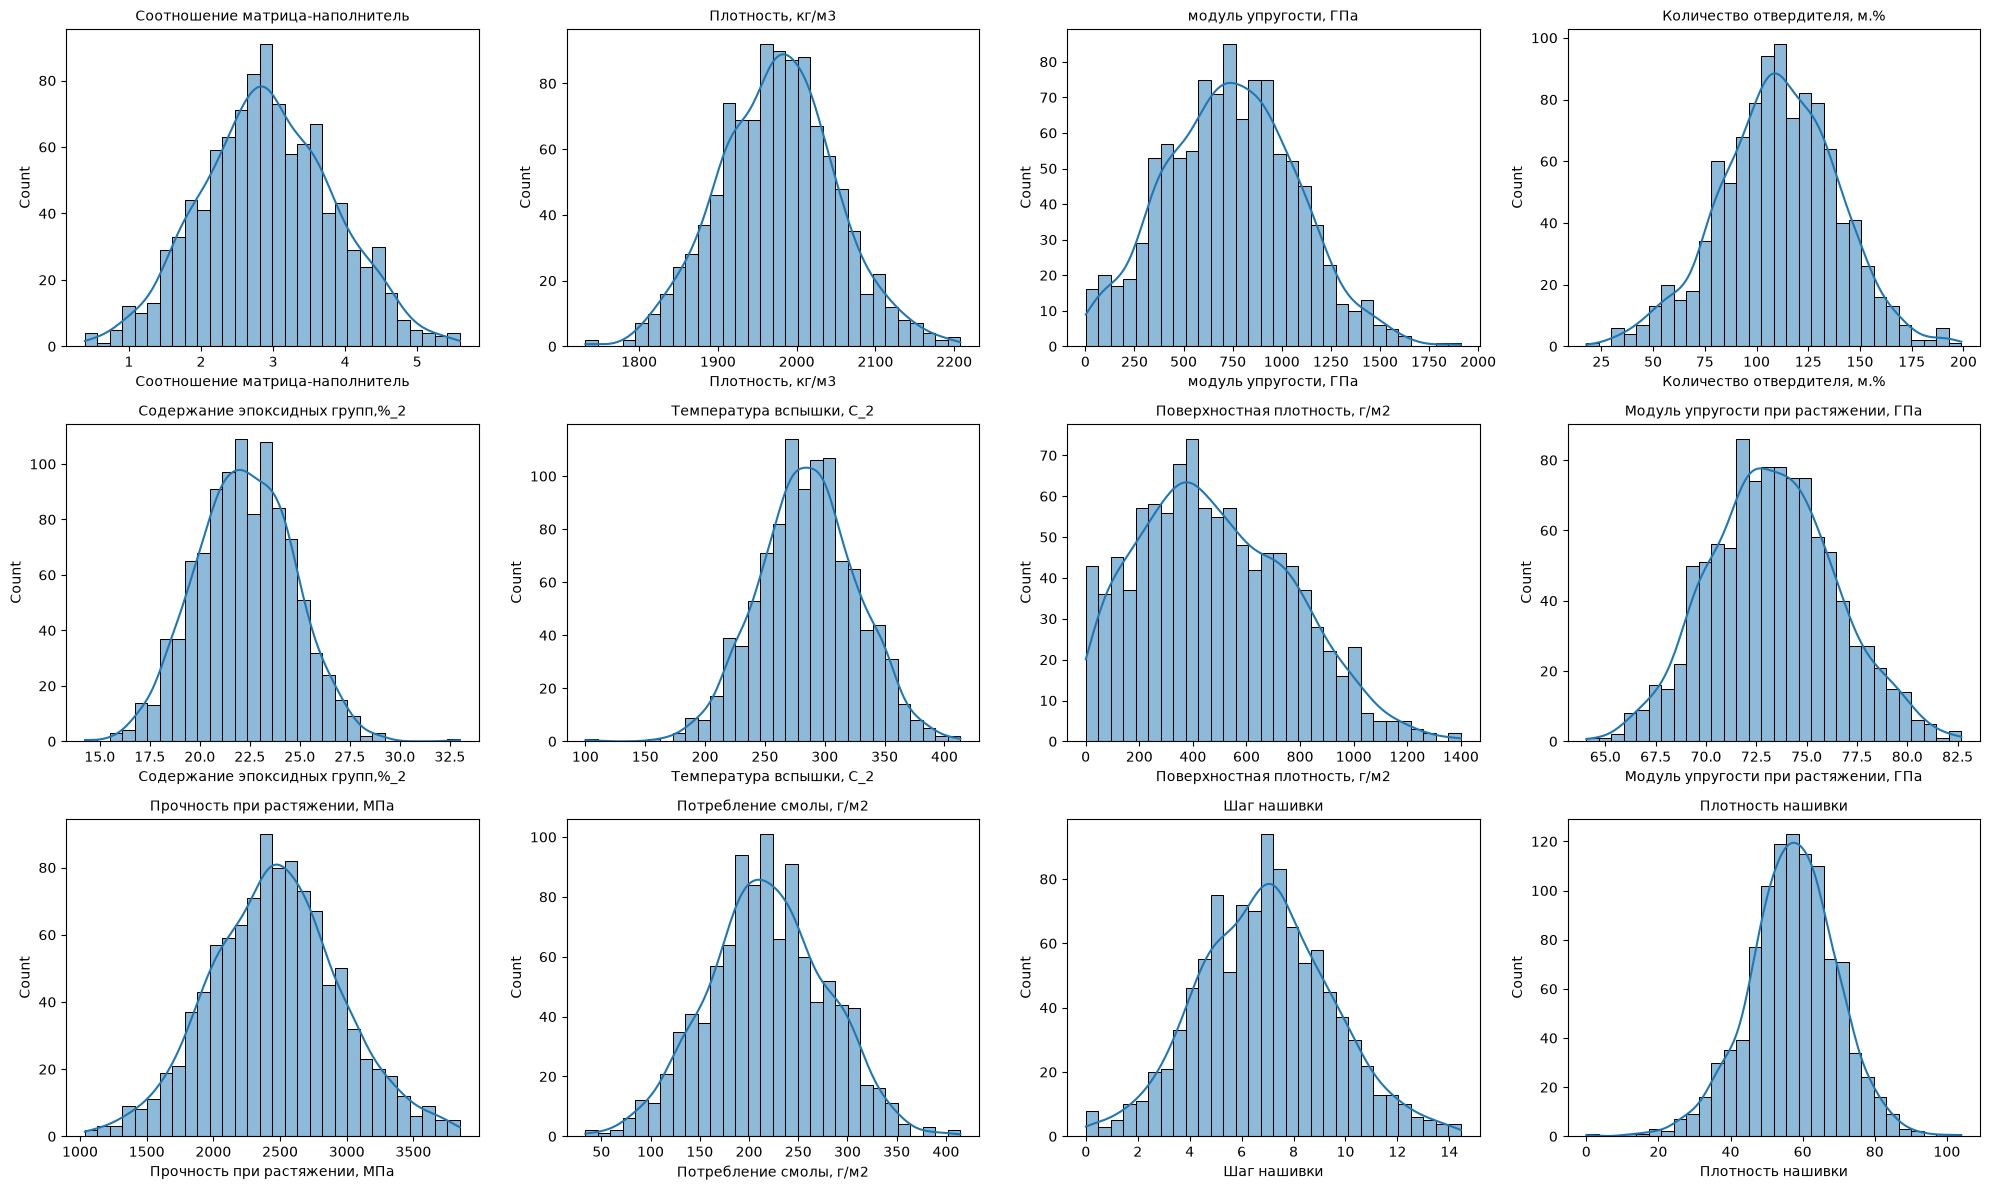

In [6]:
cols = df.columns.tolist()
cols.remove('Угол нашивки, град')

fig, axes = plt.subplots(3, 4, figsize=(20, 12))

for ax, col in zip(axes.ravel(), cols):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(col, fontsize=10)

plt.tight_layout()
plt.show()

**Выводы по распределениям:**
- распределения большинства признаков симметричны, но некоторые имеют «тяжёлые хвосты» — это необходимо учитывать при нормализации;

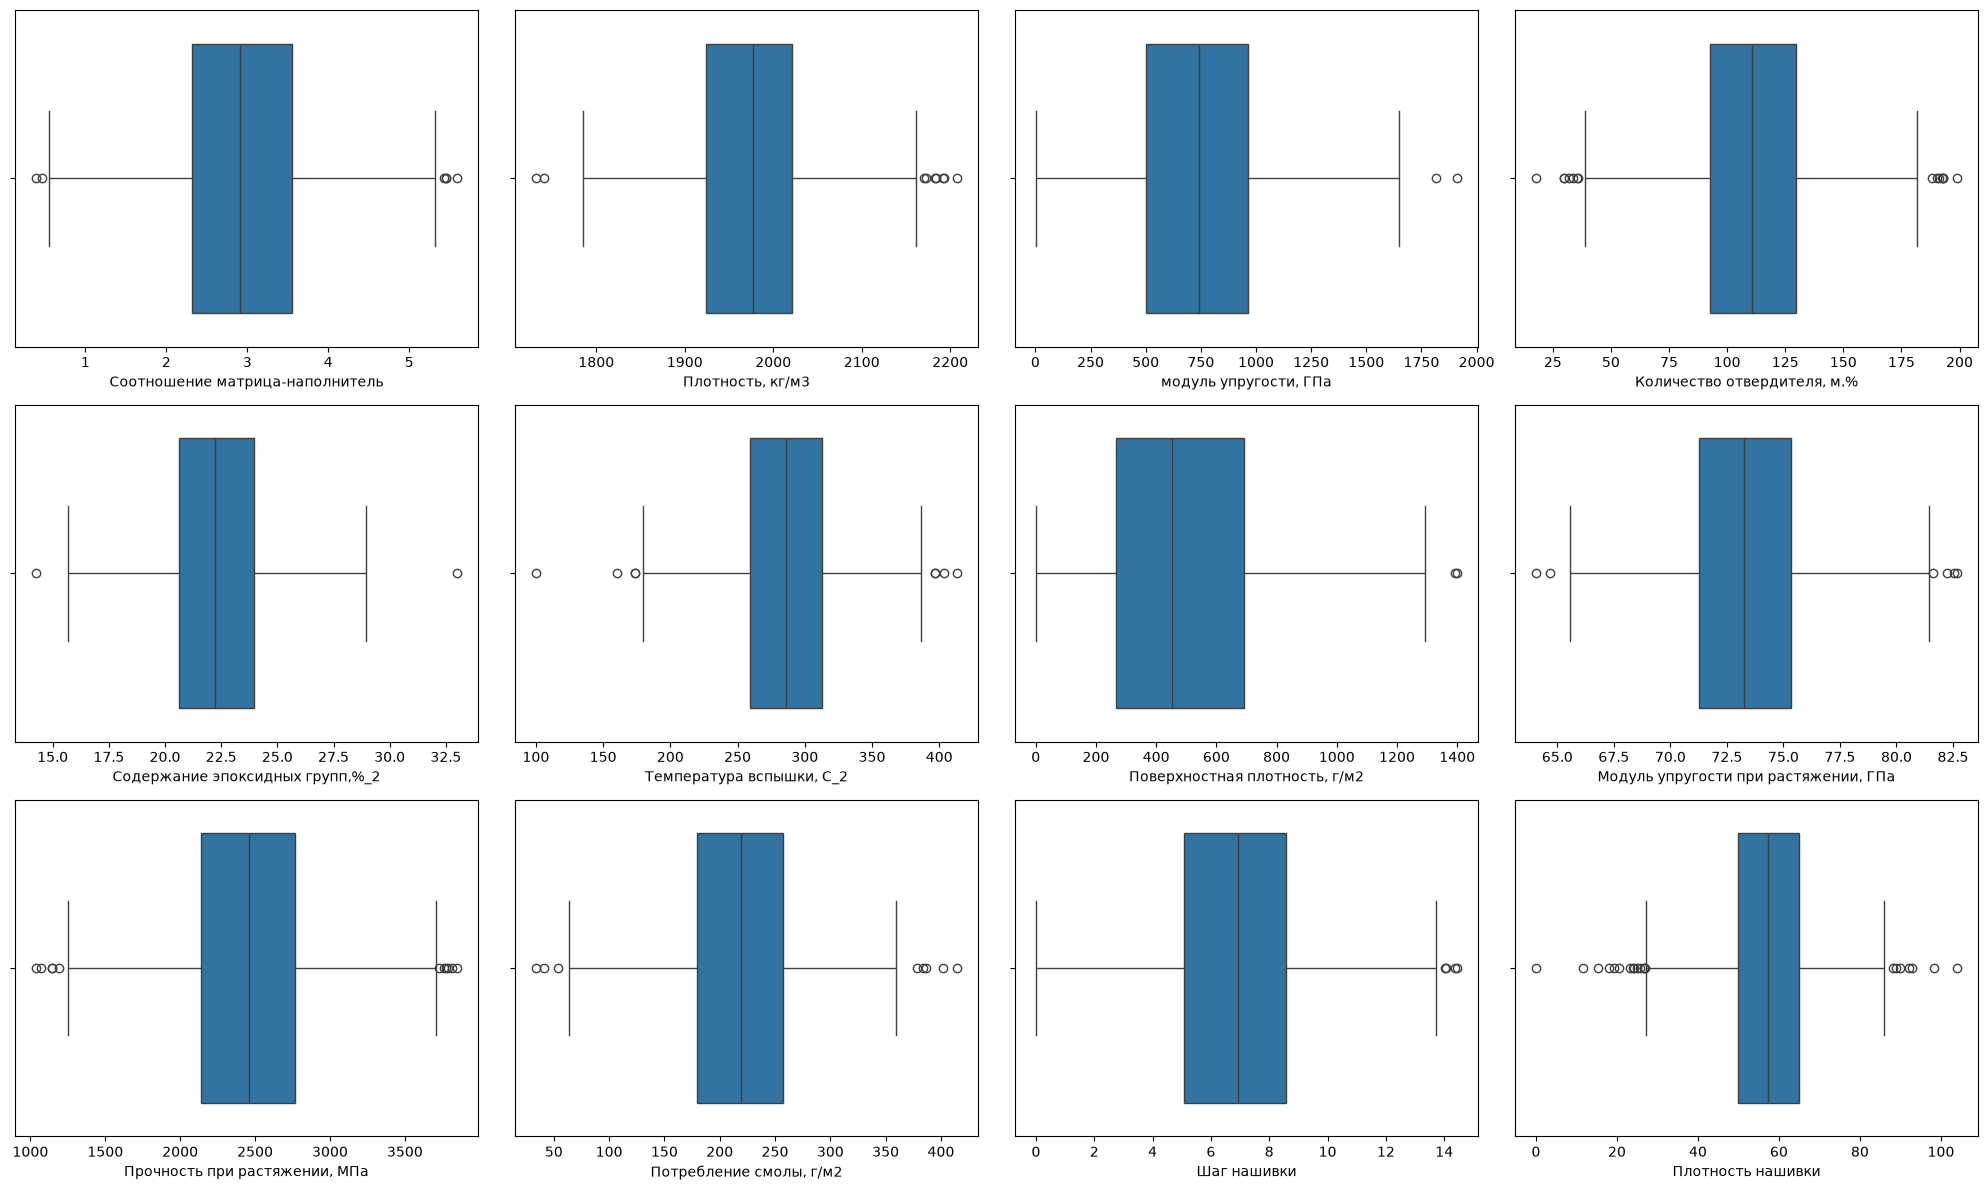

In [7]:
fig, axes = plt.subplots(3, 4, figsize=(20, 12)) 

for ax, col in zip(axes.ravel(), cols):
    sns.boxplot(x=df[col], ax=ax)

plt.tight_layout()
plt.show()

### 3.2 Анализ выбросов

Для оценки выбросов применим правило межквартильного размаха.

In [8]:
for col in cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = df[(df[col] < low) | (df[col] > high)]
    print(f'{col}: кондидатов в выбросы: {len(outliers)} ({len(outliers)/len(df)*100:.1f}%)')

Соотношение матрица-наполнитель: кондидатов в выбросы: 6 (0.6%)
Плотность, кг/м3: кондидатов в выбросы: 9 (0.9%)
модуль упругости, ГПа: кондидатов в выбросы: 2 (0.2%)
Количество отвердителя, м.%: кондидатов в выбросы: 14 (1.4%)
Содержание эпоксидных групп,%_2: кондидатов в выбросы: 2 (0.2%)
Температура вспышки, С_2: кондидатов в выбросы: 8 (0.8%)
Поверхностная плотность, г/м2: кондидатов в выбросы: 2 (0.2%)
Модуль упругости при растяжении, ГПа: кондидатов в выбросы: 6 (0.6%)
Прочность при растяжении, МПа: кондидатов в выбросы: 11 (1.1%)
Потребление смолы, г/м2: кондидатов в выбросы: 8 (0.8%)
Шаг нашивки: кондидатов в выбросы: 4 (0.4%)
Плотность нашивки: кондидатов в выбросы: 21 (2.1%)


Выбросы, выявленные по правилу межквартильного размаха, составляют не более двух процентов выборки по каждому признаку. Содержательный анализ показывает, что все эти значения физически правдоподобны, поэтому удалять их нецелесообразно — они несут информацию о редких, но возможных составах композитов.

Отдельного внимания заслуживает признак «Плотность нашивки»: в данных присутствует значение, равное нулю.

In [9]:
df[df['Плотность нашивки'] == 0]

,Соотношение матрица-наполнитель,"Плотность, кг/м3","модуль упругости, ГПа","Количество отвердителя, м.%","Содержание эпоксидных групп,%_2","Температура вспышки, С_2","Поверхностная плотность, г/м2","Модуль упругости при растяжении, ГПа","Прочность при растяжении, МПа","Потребление смолы, г/м2","Угол нашивки, град",Шаг нашивки,Плотность нашивки
19,3.532338,1980.0,1183.0,111.86,22.267857,284.615385,1010.0,78.0,2000.0,300.0,0,0.0,0.0


In [10]:
zero_share = (df['Плотность нашивки'] == 0).sum() * 100 / len(df)
print(f'Доля записей с нулевой плотностью нашивки: {zero_share:.2f} %')

Доля записей с нулевой плотностью нашивки: 0.10 %


Нулевая плотность нашивки физически невозможна; дополнительный анализ показал, что у этой же записи нулевой и шаг нашивки, что указывает на ошибку регистрации, а не на реальный состав. Поскольку такая запись одна (0,1 процента выборки), принято решение исключить её из дальнейшего анализа.

In [11]:
df = df[df['Плотность нашивки'] > 0].reset_index(drop=True)
print('Размер выборки после удаления ошибочной записи:', df.shape)

Размер выборки после удаления ошибочной записи: (1022, 13)


### 3.3 Корреляция числовых признаков

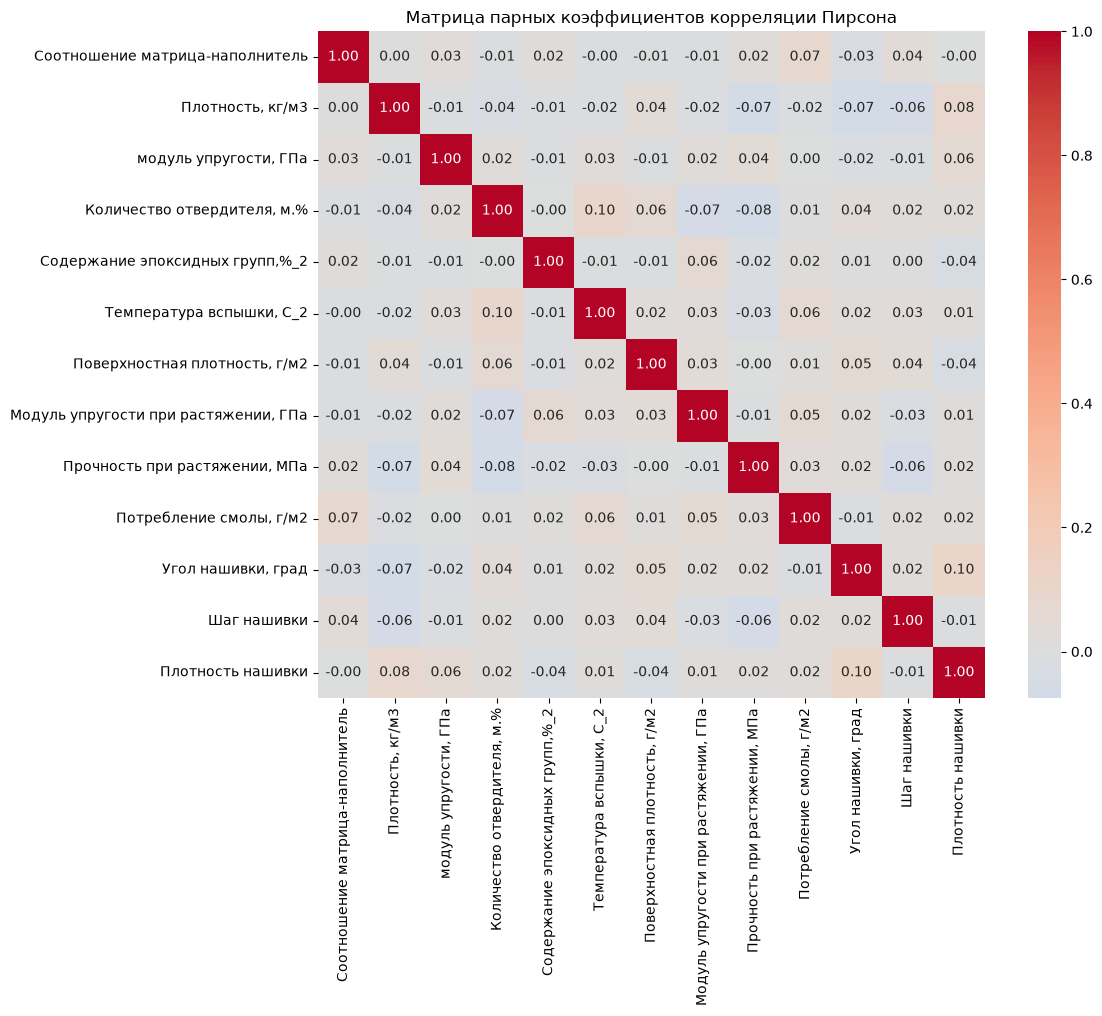

In [13]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Матрица парных коэффициентов корреляции Пирсона')
plt.tight_layout()
plt.show()

**Выводы по корреляционному анализу:**
- сильных линейных корреляций между признаками не выявлено: все парные коэффициенты корреляции по модулю меньше 0,5, следовательно, мультиколлинеарность отсутствует, и удалять признаки по этому критерию не требуется;
- корреляция входных признаков с целевыми переменными слабая. Это ещё не значит, что связи нет: коэффициент Пирсона видит только линейные зависимости. Поэтому дальше проверяем нелинейные модели и меру взаимной информации.

## 4. Предобработка данных

### 4.1 Бинарное кодирование признака «Угол нашивки, град»

Признак принимает только два значения (0 и 90 градусов). Для бинарного признака замена значений на 0 и 1 эквивалентна one-hot кодированию (из двух one-hot колонок одна всегда избыточна), поэтому применяем простую замену: 0 на 0, 90 на 1.

In [14]:
df['Угол нашивки, град'] = df['Угол нашивки, град'].replace(90, 1)
df['Угол нашивки, град']

0       0
1       0
2       0
3       0
4       0
       ..
1017    1
1018    1
1019    1
1020    1
1021    1
Name: Угол нашивки, град, Length: 1022, dtype: int64

### 4.2 Нормализация

In [15]:
targets = ['Модуль упругости при растяжении, ГПа', 'Прочность при растяжении, МПа']

# Из признаков убираем ОБЕ целевые переменные — иначе одна целевая «подсматривает» в другую (утечка данных)
X = df.drop(columns=targets)

y_elasticity = df['Модуль упругости при растяжении, ГПа']
y_strength = df['Прочность при растяжении, МПа']

print('Признаков в X:', X.shape[1])
print(X.columns.tolist())

Признаков в X: 11
['Соотношение матрица-наполнитель', 'Плотность, кг/м3', 'модуль упругости, ГПа', 'Количество отвердителя, м.%', 'Содержание эпоксидных групп,%_2', 'Температура вспышки, С_2', 'Поверхностная плотность, г/м2', 'Потребление смолы, г/м2', 'Угол нашивки, град', 'Шаг нашивки', 'Плотность нашивки']


In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# Общий X, одинаковый random_state — строки в обоих сплитах совпадают
X_train, X_test, y_elasticity_train, y_elasticity_test = train_test_split(
    X, y_elasticity, test_size=0.3, random_state=RANDOM_STATE)

_, _, y_strength_train, y_strength_test = train_test_split(
    X, y_strength, test_size=0.3, random_state=RANDOM_STATE)

# Отдельный скейлер под каждую задачу
scaler_elasticity = MinMaxScaler()
X_elasticity_train_scaled = scaler_elasticity.fit_transform(X_train)
X_elasticity_test_scaled = scaler_elasticity.transform(X_test)

scaler_strength = MinMaxScaler()
X_strength_train_scaled = scaler_strength.fit_transform(X_train)
X_strength_test_scaled = scaler_strength.transform(X_test)

Графики распределения после нормализации

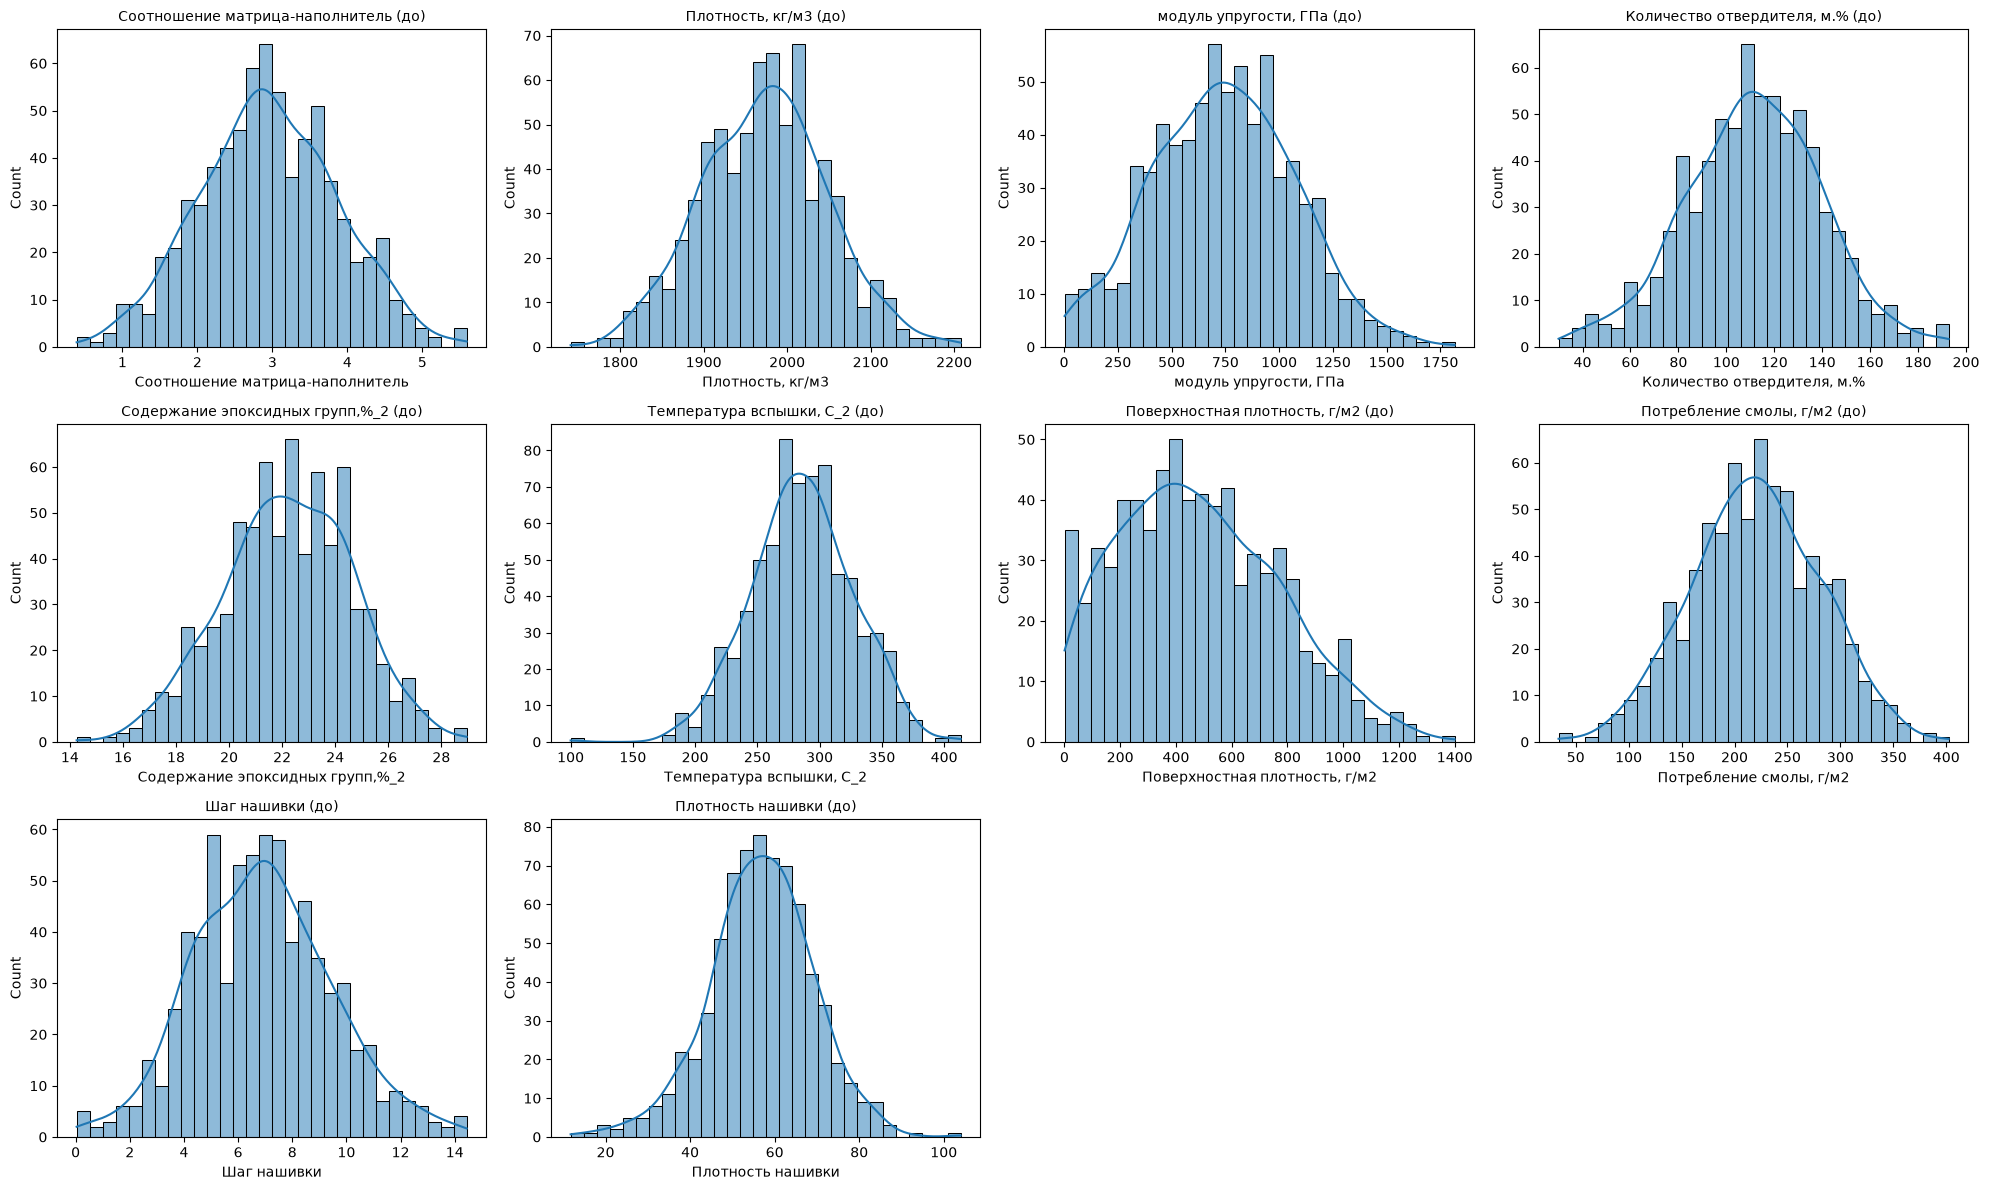

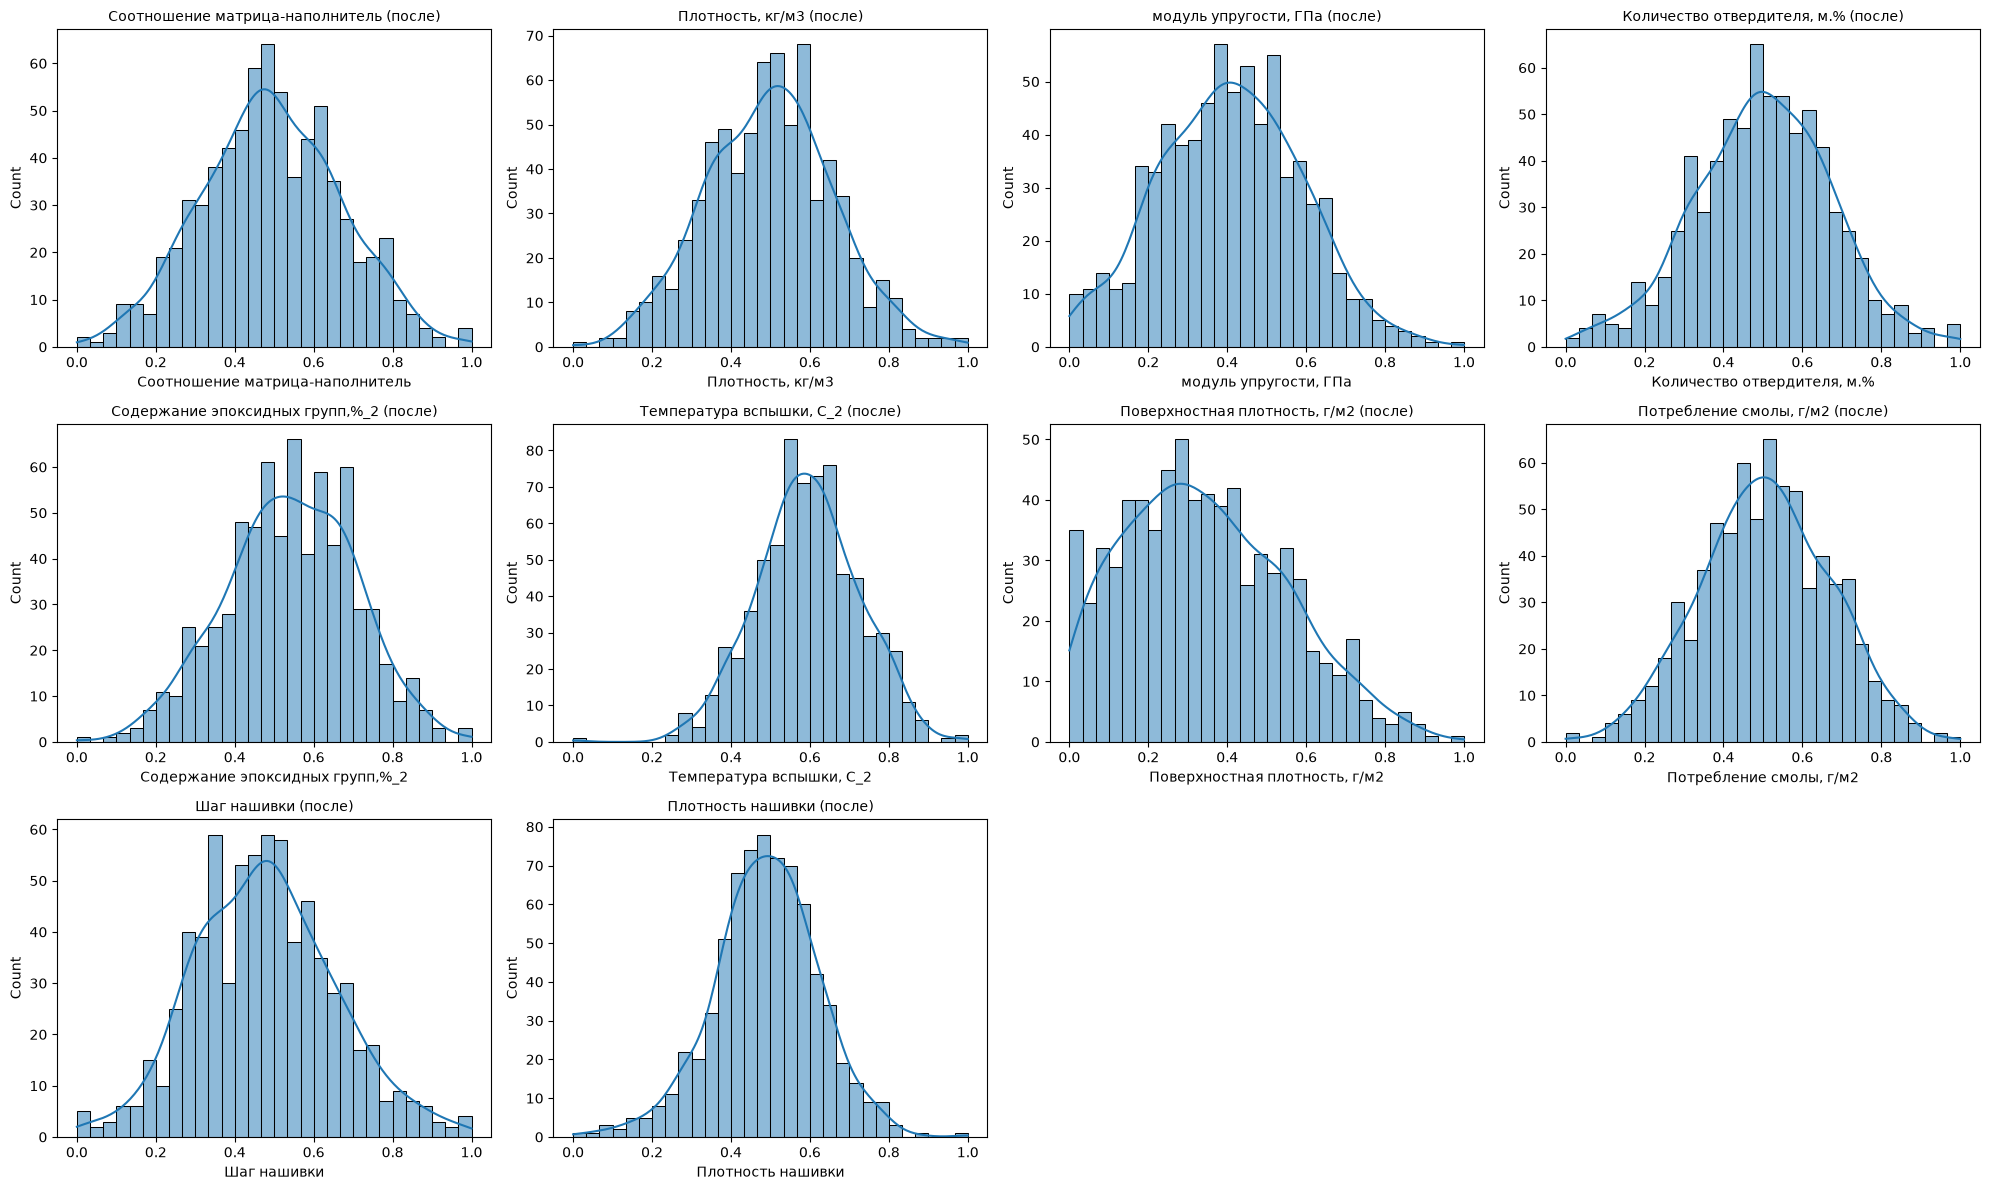

In [17]:
# Оборачиваем нормализованный массив обратно в DataFrame
X_train_scaled_df = pd.DataFrame(
    X_elasticity_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

cols_plot = X_train.columns.tolist()
cols_plot.remove('Угол нашивки, град')   # бинарный признак (0/1), на графиках не нужен

# До нормализации
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, col in zip(axes.ravel(), cols_plot):
    sns.histplot(X_train[col], bins=30, kde=True, ax=ax)
    ax.set_title(f'{col} (до)', fontsize=10)
for ax in axes.ravel()[len(cols_plot):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

# После нормализации
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, col in zip(axes.ravel(), cols_plot):
    sns.histplot(X_train_scaled_df[col], bins=30, kde=True, ax=ax)
    ax.set_title(f'{col} (после)', fontsize=10)
for ax in axes.ravel()[len(cols_plot):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [18]:
# Минимальные и максимальные значения до и после нормализации
summary = pd.DataFrame({
    'min_до': X_train.min(),
    'max_до': X_train.max(),
    'min_после': X_train_scaled_df.min(),
    'max_после': X_train_scaled_df.max()
})
summary.round(3)

,min_до,max_до,min_после,max_после
Соотношение матрица-наполнитель,0.389,5.592,0.0,1.0
"Плотность, кг/м3",1740.657,2207.773,0.0,1.0
"модуль упругости, ГПа",2.437,1815.865,0.0,1.0
"Количество отвердителя, м.%",30.000,192.705,0.0,1.0
"Содержание эпоксидных групп,%_2",14.255,28.955,0.0,1.0
"Температура вспышки, С_2",100.000,413.273,0.0,1.0
"Поверхностная плотность, г/м2",0.604,1399.542,0.0,1.0
"Потребление смолы, г/м2",33.803,402.164,0.0,1.0
"Угол нашивки, град",0.000,1.000,0.0,1.0
Шаг нашивки,0.038,14.441,0.0,1.0


## 5. Модели машинного обучения и сравнение с baseline

Сравниваются линейная регрессия, k ближайших соседей, случайный лес, градиентный бустинг scikit-learn и HistGradientBoosting. **Обязательная точка отсчёта — baseline** (`DummyRegressor`): он всегда предсказывает среднее по обучающей выборке. Модель имеет смысл, только если она лучше baseline.

Подбор гиперпараметров: GridSearchCV по 10 блокам на обучающей части (70 %), нормализация внутри Pipeline, чтобы не было утечки данных.

In [21]:
from sklearn.model_selection import GridSearchCV, RepeatedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    'Baseline (среднее)': (DummyRegressor(), {}),
    'Линейная регрессия': (LinearRegression(), {}),
    'k ближайших соседей': (KNeighborsRegressor(), {'model__n_neighbors': [5, 15, 50], 'model__weights': ['uniform', 'distance']}),
    'Случайный лес': (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
                      {'model__n_estimators': [200], 'model__max_depth': [5, 10, None], 'model__min_samples_leaf': [1, 10]}),
    'Градиентный бустинг': (GradientBoostingRegressor(random_state=RANDOM_STATE),
                            {'model__n_estimators': [100, 200], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [2, 3]}),
    'HistGradientBoosting': (HistGradientBoostingRegressor(random_state=RANDOM_STATE),
                             {'model__max_depth': [2, 3], 'model__learning_rate': [0.03, 0.1]}),
}
y_split = {TARGET_ELASTICITY: (y_elasticity_train, y_elasticity_test),
           TARGET_STRENGTH: (y_strength_train, y_strength_test)}

results, best_pipelines = [], {}
for tar, (y_tr, y_te) in y_split.items():
    for name, (model, grid) in models.items():
        pipe = Pipeline([('scaler', MinMaxScaler()), ('model', model)])
        search = GridSearchCV(pipe, grid, cv=10, scoring='neg_mean_absolute_error', n_jobs=-1).fit(X_train, y_tr)
        best = search.best_estimator_
        best_pipelines[(tar, name)] = best
        p_tr, p_te = best.predict(X_train), best.predict(X_test)
        results.append({'Целевая переменная': tar, 'Модель': name,
                        'MAE train': mean_absolute_error(y_tr, p_tr), 'MAE test': mean_absolute_error(y_te, p_te),
                        'RMSE test': np.sqrt(mean_squared_error(y_te, p_te)),
                        'R² train': r2_score(y_tr, p_tr), 'R² test': r2_score(y_te, p_te)})

results_df = pd.DataFrame(results)
results_df.round(3)

,Целевая переменная,Модель,MAE train,MAE test,RMSE test,R² train,R² test
0,"Модуль упругости при растяжении, ГПа",Baseline (среднее),2.562,2.357,2.939,0.000,-0.000
1,"Модуль упругости при растяжении, ГПа",Линейная регрессия,2.539,2.370,2.945,0.020,-0.004
2,"Модуль упругости при растяжении, ГПа",k ближайших соседей,2.538,2.359,2.935,0.026,0.003
3,"Модуль упругости при растяжении, ГПа",Случайный лес,2.259,2.358,2.954,0.219,-0.010
4,"Модуль упругости при растяжении, ГПа",Градиентный бустинг,2.336,2.357,2.960,0.172,-0.014
5,"Модуль упругости при растяжении, ГПа",HistGradientBoosting,2.418,2.348,2.940,0.106,-0.001
6,"Прочность при растяжении, МПа",Baseline (среднее),376.180,398.881,500.903,0.000,-0.026
7,"Прочность при растяжении, МПа",Линейная регрессия,371.596,403.814,503.319,0.025,-0.036
8,"Прочность при растяжении, МПа",k ближайших соседей,0.000,401.278,501.851,1.000,-0.030
9,"Прочность при растяжении, МПа",Случайный лес,331.704,396.981,497.030,0.239,-0.010


Одно разбиение 70/30 даёт шумную оценку: на ~300 тестовых записях разница в доли процента может быть случайной. Поэтому дополнительно оценим те же модели (с найденными гиперпараметрами) повторной кросс-валидацией 5 блоков × 3 повтора на всей выборке и посмотрим разброс.

In [22]:
cv_rep = RepeatedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
cv_rows = []
for tar in TARGETS:
    for name in models:
        r = cross_validate(best_pipelines[(tar, name)], X, df[tar], cv=cv_rep,
                           scoring=['r2', 'neg_mean_absolute_error'], n_jobs=-1)
        cv_rows.append({'Целевая переменная': tar, 'Модель': name,
                        'R² (CV)': r['test_r2'].mean(), '± SD': r['test_r2'].std(),
                        'MAE (CV)': -r['test_neg_mean_absolute_error'].mean()})
cv_df = pd.DataFrame(cv_rows)
cv_df.round(3)

,Целевая переменная,Модель,R² (CV),± SD,MAE (CV)
0,"Модуль упругости при растяжении, ГПа",Baseline (среднее),-0.008,0.008,2.505
1,"Модуль упругости при растяжении, ГПа",Линейная регрессия,-0.016,0.022,2.517
2,"Модуль упругости при растяжении, ГПа",k ближайших соседей,-0.018,0.024,2.517
3,"Модуль упругости при растяжении, ГПа",Случайный лес,-0.032,0.023,2.525
4,"Модуль упругости при растяжении, ГПа",Градиентный бустинг,-0.041,0.026,2.535
5,"Модуль упругости при растяжении, ГПа",HistGradientBoosting,-0.025,0.022,2.520
6,"Прочность при растяжении, МПа",Baseline (среднее),-0.007,0.010,383.245
7,"Прочность при растяжении, МПа",Линейная регрессия,-0.014,0.036,386.280
8,"Прочность при растяжении, МПа",k ближайших соседей,-0.019,0.021,385.994
9,"Прочность при растяжении, МПа",Случайный лес,-0.015,0.026,386.757


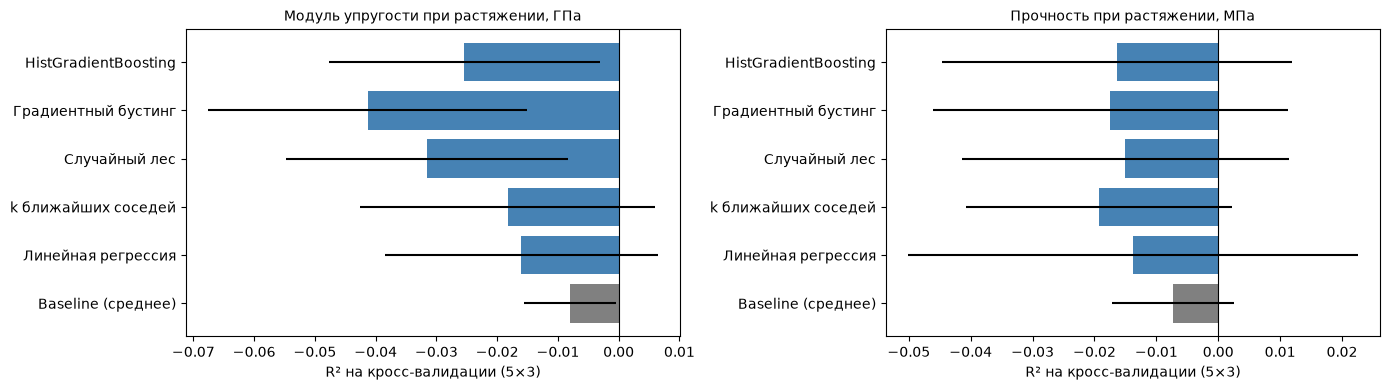

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, tar in zip(axes, TARGETS):
    d = cv_df[cv_df['Целевая переменная'] == tar]
    colors = ['grey' if m.startswith('Baseline') else 'steelblue' for m in d['Модель']]
    ax.barh(d['Модель'], d['R² (CV)'], xerr=d['± SD'], color=colors)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(tar, fontsize=10); ax.set_xlabel('R² на кросс-валидации (5×3)')
plt.tight_layout(); plt.show()

**Выводы по разделу:**
- для обеих целевых переменных R² всех моделей близок к нулю или отрицателен; на отложенной выборке разница с baseline по MAE доли процента, то есть в пределах случайности;
- на повторной кросс-валидации лучший результат у самого baseline: каждая модель предсказывает чуть хуже, чем просто среднее значение;
- сложные модели на обучающей выборке показывают R² 0,1–0,2, но на тесте около нуля: они запоминают шум, а не закономерность.

Итоговые модели для приложения (случайный лес) сохранены, но их прогноз практически совпадает со средним значением.

## 6. Перестановочный тест и взаимная информация

Отрицательный R² может означать и «модели плохие», и «предсказывать нечего». Чтобы различить эти случаи, используем два метода.

**Перестановочный тест** (`permutation_test_score`): целевая переменная случайно перемешивается 100 раз, и модель каждый раз обучается заново. Если качество на настоящих данных не выше, чем на перемешанных, то связи между признаками и целью нет. p-значение - доля перестановок, где качество было не хуже, чем на настоящих данных.

**Взаимная информация** (mutual information) ловит и нелинейные зависимости. Сравниваем её с тем, что получается на перемешанной цели (95-й перцентиль - граница «случайного» уровня).

In [24]:
from sklearn.model_selection import KFold, permutation_test_score
from sklearn.feature_selection import mutual_info_regression

perm_rows = []
X_ratio = df.drop(columns=TARGETS + [TARGET_RATIO])
tasks = {TARGET_ELASTICITY: X, TARGET_STRENGTH: X, TARGET_RATIO: X_ratio}
for tar, Xt in tasks.items():
    score, perm_scores, p = permutation_test_score(
        RandomForestRegressor(n_estimators=100, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1),
        Xt, df[tar], cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
        scoring='r2', n_permutations=100, random_state=RANDOM_STATE)
    perm_rows.append({'Целевая переменная': tar, 'R² на настоящих данных': score,
                      'R² на перемешанных (среднее)': perm_scores.mean(), 'p-значение': p})
perm_df = pd.DataFrame(perm_rows)
perm_df.round(3)

,Целевая переменная,R² на настоящих данных,R² на перемешанных (среднее),p-значение
0,"Модуль упругости при растяжении, ГПа",-0.066,-0.050,0.832
1,"Прочность при растяжении, МПа",-0.039,-0.054,0.129
2,Соотношение матрица-наполнитель,-0.045,-0.055,0.267


In [25]:
rng = np.random.default_rng(RANDOM_STATE)
mi_rows = []
for tar, Xt in tasks.items():
    mi = mutual_info_regression(Xt, df[tar], random_state=RANDOM_STATE)
    null = np.array([mutual_info_regression(Xt, rng.permutation(df[tar].values), random_state=RANDOM_STATE)
                     for _ in range(30)])
    thr = np.quantile(null, 0.95, axis=0)
    for f, m, t in zip(Xt.columns, mi, thr):
        mi_rows.append({'Целевая переменная': tar, 'Признак': f, 'MI': m, 'Порог случайности (95 %)': t, 'Выше порога': m > t})
mi_df = pd.DataFrame(mi_rows)
print('Признаков с MI выше случайного уровня:')
print(mi_df.groupby('Целевая переменная')['Выше порога'].sum())
mi_df[mi_df['Выше порога']].round(3)

Признаков с MI выше случайного уровня:
Целевая переменная
Модуль упругости при растяжении, ГПа    2
Прочность при растяжении, МПа           5
Соотношение матрица-наполнитель         4
Name: Выше порога, dtype: int64


,Целевая переменная,Признак,MI,Порог случайности (95 %),Выше порога
6,"Модуль упругости при растяжении, ГПа","Поверхностная плотность, г/м2",0.100,0.035,True
7,"Модуль упругости при растяжении, ГПа","Потребление смолы, г/м2",0.096,0.030,True
11,"Прочность при растяжении, МПа",Соотношение матрица-наполнитель,0.064,0.037,True
15,"Прочность при растяжении, МПа","Содержание эпоксидных групп,%_2",0.045,0.043,True
17,"Прочность при растяжении, МПа","Поверхностная плотность, г/м2",0.089,0.024,True
18,"Прочность при растяжении, МПа","Потребление смолы, г/м2",0.061,0.033,True
19,"Прочность при растяжении, МПа","Угол нашивки, град",0.027,0.023,True
22,Соотношение матрица-наполнитель,"Плотность, кг/м3",0.087,0.038,True
23,Соотношение матрица-наполнитель,"модуль упругости, ГПа",0.056,0.043,True
27,Соотношение матрица-наполнитель,"Поверхностная плотность, г/м2",0.046,0.039,True


**Выводы по разделу:**
- перестановочный тест не находит связи, пригодной для прогноза, ни для одной целевой переменной: p-значения далеко за порогом 0,05, а качество на настоящих данных такое же, как на данных с перемешанной целью;
- взаимная информация для части признаков выходит за случайный уровень, но сами значения очень малы (MI ≤ 0,1): зависимости слишком слабые, чтобы модели могли обратить их в выигрыш в прогнозе (раздел 5 и раздел 7);
- значит, низкое качество моделей получается из-за свойство данных, а не выбора модели или гиперпараметров.

## 7. Нейронная сеть для рекомендации соотношения матрица-наполнитель

Задача: по свойствам компонентов рекомендовать соотношение матрица-наполнитель. Признаки: все, кроме самого соотношения и двух целевых переменных из раздела 5 (при подборе рецептуры они ещё неизвестны).

### 7.1 Базовая архитектура
Полносвязная сеть (MLP): два скрытых слоя 64 и 32 нейрона, ReLU, Dropout 0,2, оптимизатор Adam (lr = 0,001), функция потерь MAE, ранняя остановка по валидационной ошибке.

In [27]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
import tensorflow as tf
tf.get_logger().setLevel('ERROR')
from tensorflow import keras
from tensorflow.keras import layers, callbacks
from src.data import FEATURES_NN

keras.utils.set_random_seed(RANDOM_STATE)

X_nn, y_nn = df[FEATURES_NN], df[TARGET_RATIO]
X_train_nn, X_test_nn, y_train_nn, y_test_nn = train_test_split(X_nn, y_nn, test_size=0.3, random_state=RANDOM_STATE)
scaler_nn = MinMaxScaler()
X_train_nn_s = scaler_nn.fit_transform(X_train_nn)
X_test_nn_s = scaler_nn.transform(X_test_nn)


def build_mlp(hidden=(64, 32), dropout=0.2, l2=0.0, n_in=len(FEATURES_NN)):
    reg = keras.regularizers.l2(l2) if l2 else None
    m = keras.Sequential([layers.Input(shape=(n_in,))])
    for i, h in enumerate(hidden):
        m.add(layers.Dense(h, activation='relu', kernel_regularizer=reg))
        if dropout and i == 0:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(1))
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss='mae')
    return m


early_stopping = callbacks.EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
model = build_mlp()
history = model.fit(X_train_nn_s, y_train_nn, epochs=200, batch_size=32, validation_split=0.2,
                    callbacks=[early_stopping], verbose=0)

pred_nn = model.predict(X_test_nn_s, verbose=0).flatten()
baseline_pred = np.full_like(y_test_nn, y_train_nn.mean(), dtype=float)
print(f'Эпох обучения: {len(history.history["loss"])}')
print(f'MAE нейросети: {mean_absolute_error(y_test_nn, pred_nn):.3f} | R²: {r2_score(y_test_nn, pred_nn):.3f}')
print(f'MAE baseline:  {mean_absolute_error(y_test_nn, baseline_pred):.3f} | R²: {r2_score(y_test_nn, baseline_pred):.3f}')

Эпох обучения: 73
MAE нейросети: 0.748 | R²: -0.027
MAE baseline:  0.740 | R²: -0.007


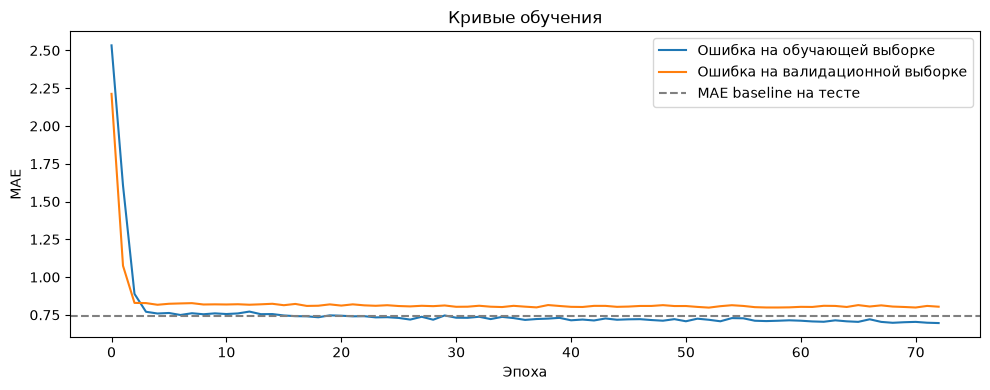

In [28]:
plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'], label='Ошибка на обучающей выборке')
plt.plot(history.history['val_loss'], label='Ошибка на валидационной выборке')
plt.axhline(mean_absolute_error(y_test_nn, baseline_pred), color='grey', ls='--', label='MAE baseline на тесте')
plt.xlabel('Эпоха'); plt.ylabel('MAE'); plt.legend(); plt.title('Кривые обучения')
plt.tight_layout(); plt.show()

### 7.2 Можно ли улучшить результат архитектурой?

Проверим 8 вариантов: от одного маленького слоя до трёх слоёв, с разной регуляризацией. Каждый вариант оценивается кросс-валидацией по 5 блокам, чтобы сравнение не зависело от одного случайного разбиения.

In [29]:
configs = {
    '16': dict(hidden=(16,), dropout=0.0),
    '16, L2': dict(hidden=(16,), dropout=0.0, l2=1e-2),
    '64-32 (базовая)': dict(hidden=(64, 32), dropout=0.2),
    '64-32, L2': dict(hidden=(64, 32), dropout=0.2, l2=1e-2),
    '128-64-32': dict(hidden=(128, 64, 32), dropout=0.2),
    '128-64-32, L2': dict(hidden=(128, 64, 32), dropout=0.3, l2=1e-2),
    '256-128-64': dict(hidden=(256, 128, 64), dropout=0.3),
    '256-128-64, L2': dict(hidden=(256, 128, 64), dropout=0.3, l2=1e-2),
}
kf = KFold(5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, cfg in {'Baseline (среднее)': None, **configs}.items():
    maes, r2s = [], []
    for tr, te in kf.split(X_nn):
        sc = MinMaxScaler().fit(X_nn.iloc[tr])
        Xtr, Xte = sc.transform(X_nn.iloc[tr]), sc.transform(X_nn.iloc[te])
        ytr, yte = y_nn.iloc[tr], y_nn.iloc[te]
        if cfg is None:
            p = np.full(len(yte), ytr.mean())
        else:
            keras.utils.set_random_seed(RANDOM_STATE)
            m = build_mlp(**cfg)
            m.fit(Xtr, ytr, epochs=200, batch_size=32, validation_split=0.2, verbose=0,
                  callbacks=[callbacks.EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)])
            p = m(Xte, training=False).numpy().flatten()
        maes.append(mean_absolute_error(yte, p)); r2s.append(r2_score(yte, p))
    rows.append({'Архитектура': name, 'MAE (CV)': np.mean(maes), 'R² (CV)': np.mean(r2s), '± SD R²': np.std(r2s)})
nn_df = pd.DataFrame(rows)
nn_df.round(3)

,Архитектура,MAE (CV),R² (CV),± SD R²
0,Baseline (среднее),0.730,-0.006,0.008
1,16,0.751,-0.058,0.015
2,"16, L2",0.739,-0.020,0.003
3,64-32 (базовая),0.749,-0.040,0.022
4,"64-32, L2",0.733,-0.010,0.007
5,128-64-32,0.764,-0.089,0.016
6,"128-64-32, L2",0.732,-0.009,0.007
7,256-128-64,0.757,-0.067,0.031
8,"256-128-64, L2",0.732,-0.009,0.008


**Выводы по разделу:**
- ни одна из 8 архитектур не обходит baseline: R² на кросс-валидации у всех около нуля или ниже;
- более сложные сети не помогают, а регуляризация лишь приближает сеть к прогнозу средним;
- это ожидаемо после раздела 6: архитектура не может найти связь, которой в данных нет. Улучшить результат можно только другими данными.

## 8. Итоги

1. **Пайплайн построен целиком:** EDA, очистка, кодирование, нормализация без утечки, шесть моделей ML с подбором гиперпараметров, нейронная сеть, Streamlit-приложение.
2. **Качество:** ни одна модель - ни ML, ни нейронная сеть любой из проверенных архитектур - не лучше прогноза средним (R² ≈ 0 на кросс-валидации).
3. **Причина в данных, а не в моделях.** Перестановочный тест не находит связи, пригодной для прогноза; взаимная информация показывает лишь очень слабые зависимости.